# c₂ distribution for every Γ₂⁻ basis pattern (Y₂Ir₂O₇)

Companion to `../figures/c2_distribution.ipynb`: c₂(**k**) is the integrand of Eq. (4curv-reduced), ∂θ/∂Q = ∫ c₂ d³k
over the unit cube of reduced coordinates. One panel per Γ₂⁻ basis pattern (Y, Ir, O48f): c₂ on the (110) plane
through Γ, periodic cubic interpolation of the 10³ production mesh (self-test base 214249, series windows
12.422 / 22.644 eV, Q = 0.01 Å), clipped to the first zone; and the concentration curves (how much of the zone carries
the response).

`END` picks the estimate: 0 = momentum-space quantities of the undistorted structure, 1 = displaced structure,
"mean".

In [1]:
# ---- settings
from pathlib import Path
ROOT = Path("/Users/treycole/Repos/axion-phonon")
DATA = ROOT / "data"
YIO_WINDOW = DATA / "Y2Ir2O7/windows/f12.422_w22.644_k8"
YIO_C2 = {m: YIO_WINDOW / f"dtheta_GM2-_p{m}_Q0.01/c2.npz" for m in (1, 2, 3)}   # step 7: k (n^3, 3) reduced, c2 (n^3, 2 ends)
YIO_WIN = YIO_WINDOW / "base/out/Y2Ir2O7.win"
YIO_LABELS = {1: "Y", 2: "Ir", 3: r"O$_{48f}$"}
YIO_GRID = 301                       # points per side of the interpolation grid
END = 0                              # 0: undistorted end, 1: displaced end, "mean"
FONT_SIZE = 8
SAVE_YIO = DATA / "Y2Ir2O7/windows/f12.422_w22.644_k8/c2_distribution_modes.png"   # or None
# ---------------


In [2]:
# ---- data
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm, TwoSlopeNorm
from scipy.ndimage import map_coordinates
from itertools import permutations, product

def cell(win):
    lines = Path(win).read_text().splitlines()
    i = next(j for j, line in enumerate(lines) if line.strip().lower() == "begin unit_cell_cart")
    rows = [line.split() for line in lines[i + 1:i + 5] if line.split() and line.split()[0].lower() not in ("ang", "bohr")][:3]
    A = np.array(rows, float)
    return A, 2 * np.pi * np.linalg.inv(A).T                      # rows a_i (Å), rows b_i (1/Å)

def pick(c2):
    return c2.real.mean(axis=-1) if END == "mean" else c2[..., END].real

# Y2Ir2O7: 10³ mesh, k = n / nk in reduced coordinates
def c2_grid(f):
    """Step 7's c2.npz (k list of the plain n^3 grid) as an (n, n, n, 2) array indexed by k = (i, j, l) / n."""
    z = np.load(f)
    n = round(len(z["k"]) ** (1 / 3))
    idx = np.rint(z["k"] * n).astype(int) % n
    g = np.full((n, n, n, 2), np.nan, complex)
    g[idx[:, 0], idx[:, 1], idx[:, 2]] = z["c2"]
    assert not np.isnan(g.real).any(), f"{f}: not the full {n}^3 grid"
    return g

c2_y = {m: pick(c2_grid(f)) for m, f in YIO_C2.items()}
A_y, B_y = cell(YIO_WIN)
for m, c in c2_y.items():
    print(f"YIO pattern {m} ({YIO_LABELS[m]}): ∂θ/∂Q = {c.mean():+.6f} rad/Å on {c.shape[0]}³")


YIO pattern 1 (Y): ∂θ/∂Q = -0.017114 rad/Å on 10³
YIO pattern 2 (Ir): ∂θ/∂Q = +0.055021 rad/Å on 10³
YIO pattern 3 (O$_{48f}$): ∂θ/∂Q = +0.063867 rad/Å on 10³


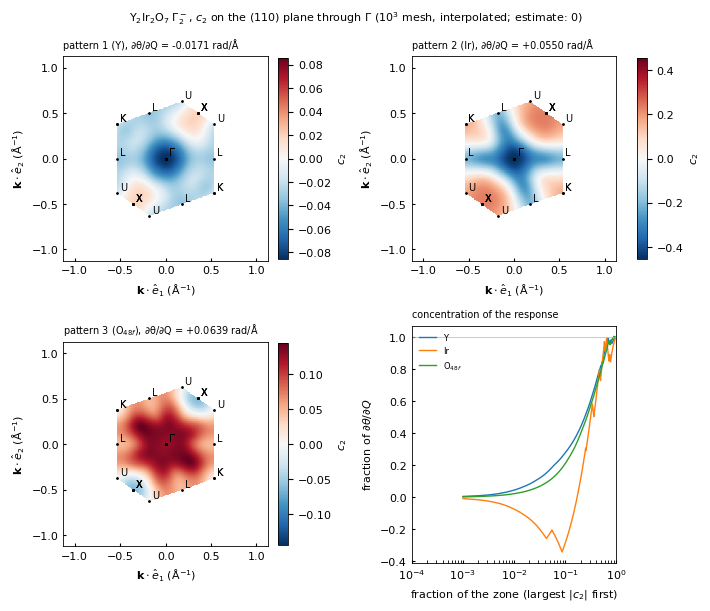

In [3]:
plt.rcParams.update({"font.size": FONT_SIZE, "axes.linewidth": 0.6})
# ---- Y2Ir2O7: (110) plane through Γ for each pattern, and the concentration curves
e1 = B_y[0] / np.linalg.norm(B_y[0])
e2 = B_y[1] - (B_y[1] @ e1) * e1
e2 /= np.linalg.norm(e2)
normal = np.cross(e1, e2)
R = 1.05 * np.linalg.norm(B_y, axis=1).max()
s = np.linspace(-R, R, YIO_GRID)
S, T = np.meshgrid(s, s, indexing="xy")
kc = S[..., None] * e1 + T[..., None] * e2
kr = kc @ np.linalg.inv(B_y)
G = np.array(np.meshgrid(*[range(-2, 3)] * 3, indexing="ij")).reshape(3, -1).T @ B_y
G = G[np.linalg.norm(G, axis=1) > 1e-9]
inside = np.all(np.einsum("ijk,gk->ijg", kc, G) <= 0.5 * (G ** 2).sum(1), axis=-1)
a = np.linalg.norm(A_y[0]) * np.sqrt(2)                          # cubic lattice constant
pts = {r"$\Gamma$": (0, 0, 0), "X": (0, 0, 1), "L": (0.5, 0.5, 0.5), "K": (0.75, 0.75, 0), "U": (0.25, 0.25, 1), "W": (0.5, 0, 1)}
labels_in_plane = []
for name, p in pts.items():
    for perm in set(permutations(p)):
        for sg in product((1, -1), repeat=3):
            k = 2 * np.pi / a * np.array(perm) * sg
            if abs(k @ normal) < 1e-6 and np.all(np.abs(k @ np.array([e1, e2]).T) <= R):
                labels_in_plane.append((name, k @ e1, k @ e2))

fig, axes = plt.subplots(2, 2, figsize=(7.0, 6.0), layout="constrained")
for ax, (m, c) in zip(axes.ravel()[:3], c2_y.items()):
    n = c.shape[0]
    mp = np.where(inside, map_coordinates(c, (kr % 1.0 * n).transpose(2, 0, 1), order=3, mode="grid-wrap"), np.nan)
    v = np.nanmax(np.abs(mp))
    im = ax.pcolormesh(S, T, mp, cmap="RdBu_r", norm=TwoSlopeNorm(0, -v, v), shading="auto")
    for name, u, w in labels_in_plane:
        ax.plot(u, w, "k.", ms=2)
        ax.annotate(name, (u, w), xytext=(2, 2), textcoords="offset points", fontsize=FONT_SIZE - 1)
    ax.set(aspect="equal", xlabel=r"$\mathbf{k}\cdot\hat e_1$ (Å$^{-1}$)", ylabel=r"$\mathbf{k}\cdot\hat e_2$ (Å$^{-1}$)")
    fig.colorbar(im, ax=ax, label=r"$c_2$", shrink=0.85)
    ax.set_title(f"pattern {m} ({YIO_LABELS[m]}), ∂θ/∂Q = {c.mean():+.4f} rad/Å", loc="left", fontsize=FONT_SIZE - 1)
ax = axes[1, 1]
for m, c in c2_y.items():
    f = c.ravel()[np.argsort(-np.abs(c.ravel()))]
    ax.plot(np.arange(1, f.size + 1) / f.size, np.cumsum(f) / f.sum(), lw=1, label=YIO_LABELS[m])
ax.axhline(1, color="0.7", lw=0.5)
ax.set(xscale="log", xlim=(1e-4, 1), xlabel="fraction of the zone (largest $|c_2|$ first)", ylabel=r"fraction of $\partial\theta/\partial Q$")
ax.legend(fontsize=FONT_SIZE - 2, frameon=False, loc="upper left")
ax.set_title("concentration of the response", loc="left", fontsize=FONT_SIZE - 1)
for ax in axes.ravel():
    ax.tick_params(direction="in", length=2, which="both")
fig.suptitle(f"Y$_2$Ir$_2$O$_7$ $\\Gamma_2^-$, $c_2$ on the (110) plane through $\\Gamma$ (10$^3$ mesh, interpolated; estimate: {END!r})", fontsize=FONT_SIZE)
if SAVE_YIO:
    fig.savefig(SAVE_YIO, dpi=250)
plt.show()
plt.rcdefaults()
